# AWT - PCs analysis

Analysis of the principal components (PCs) of the SST + MSL PCA computed in
`01_Global_AWT_SST_MSLP_no_standarize_pca_parabola_ALL_lat_corrected.ipynb`: how much variance they
explain, how much of the main climate indices they capture and at which time scales they vary.

Each index is reconstructed with a multiple linear regression on the first *n* PCs:

$$\text{index}(t) \approx \beta_0 + \sum_{k=1}^{n} \beta_k \, PC_k(t)$$

and the skill is measured as the correlation between the observed and the reconstructed index.

Besides the indices saved by notebook 01, the ENSO Longitude Index (**ELI**, ggweather) and the
Relative Oceanic Niño Index (**RONI**, NOAA CPC) are added when loading the data (`add_indices`).

All the indices are **detrended** with a quadratic (parabola) trend over the PC period, the same trend
removed from the SST and MSL fields in notebook 01 (`DETREND_DEG` in the loading cell).
Otherwise, trend-dominated indices (AMO, PDO) cannot be reproduced by PCs computed from detrended fields.

**Contents**
1. **Leading PCs**: variance explained by each PC and time series of the first ones.
2. **Relationships between the indices**: correlation matrix between the climate indices.
3. **Correlation of each index with each PC**: which PCs carry the signal of each index.
4. **Regression with all the PCs (in-sample)**: how well each index is reproduced by the 100 PCs.
5. **Regression skill vs number of PCs**: in-sample vs cross-validated skill, to detect overfitting.
6. **Frequency analysis of the PCs**: variance of each PC by period band (intra-annual, interannual,
   decadal), band-pass components of the leading PCs and seasonal modulation of their amplitude.

All the functions are in `utils/pcs_analysis.py` and `utils/climate_indices.py`.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

from utils import PURPLE, ORANGE
from utils.plotting import plot_explained_variance
from utils.climate_indices import add_indices, plot_regression_summary, plot_regression_vs_npcs
from utils.pcs_analysis import (estimate_explained_variance, skill_vs_npcs, pc_index_correlation, top_pcs_table,
                                index_correlation_matrix, plot_index_correlation, plot_pc_index_heatmap,
                                plot_annotated_matrix, regular_monthly_pcs, band_variance,
                                seasonal_std, seasonal_std_significance, plot_band_fractions,
                                plot_band_decomposition, BANDS, CMAP_DIV)

In [2]:
p_indices = os.path.join('inputs', 'climate_indices.nc')  # created by notebook 00b
p_pcs_indices = os.path.join('outputs', 'pca_SST_MSLP_ALL_lat_corr_climate_indexes.nc')
p_predictor = os.path.join('outputs', 'sst_detrend_monthly_1day_lat_corr.nc')

pcs_indices = xr.load_dataset(p_pcs_indices)

# all the indices are re-read from p_indices and detrended with a polynomial of degree DETREND_DEG
# (2 = same parabola as the SST / MSL fields; None = indices as published). ELI and RONI are added
# to the indices saved by notebook 01.
DETREND_DEG = 2
names = list(dict.fromkeys(list(pcs_indices.index_name.values.astype(str)) + ['ELI', 'RONI']))
pcs_indices = add_indices(pcs_indices, names, p_indices, detrend_deg=DETREND_DEG, overwrite=True)

# files created before the explained variance was saved in notebook 01
if 'explained_variance_ratio' not in pcs_indices:
    pcs_indices['explained_variance_ratio'] = estimate_explained_variance(pcs_indices, p_predictor)
pcs_indices

<xarray.Dataset> Size: 433kB
Dimensions:                   (time: 853, n_pcs: 100, climate_index: 12,
                               n_component: 422)
Coordinates:
  * time                      (time) datetime64[ns] 7kB 1950-01-01 ... 2024-0...
  * n_pcs                     (n_pcs) int64 800B 0 1 2 3 4 5 ... 95 96 97 98 99
Dimensions without coordinates: climate_index, n_component
Data variables: (12/16)
    PCs                       (time, n_pcs) float32 341kB -37.62 ... 1.548
    nao                       (time) float64 7kB 1.191 0.67 ... -0.398 -0.7324
    ao                        (time) float64 7kB 0.3763 1.062 ... 0.2842 0.4327
    amo                       (time) float64 7kB -0.07493 -0.1736 ... 0.2208
    scand                     (time) float64 7kB 0.4863 -1.233 ... -0.5456
    olr                       (time) float64 7kB nan nan nan ... -1.455 -0.3886
    ...                        ...
    sam                       (time) float64 7kB nan nan nan nan ... nan nan nan
    index_correlation         (climate_index) float64 96B 0.7904 ... 0.9676
    index_name                (climate_index) <U4 192B 'NAO' 'AO' ... 'RONI'
    explained_variance_ratio  (n_component) float32 2kB 0.1433 ... 0.000108
    eli                       (time) float64 7kB nan nan nan ... 17.0 -4.707
    roni                      (time) float64 7kB -1.285 -1.185 ... 1.386 0.3989

## 1. Leading PCs

### 1.1 Explained variance

Bars: percentage of the variance of the SST + MSL predictor explained by each PC. Black line (right axis):
cumulative explained variance; the dashed lines mark the number of PCs needed to reach 50%, 70% and 90%.

The PCA keeps the components needed to explain 98% of the variance, but only the first 100 PCs are stored
and used in the rest of the notebook.

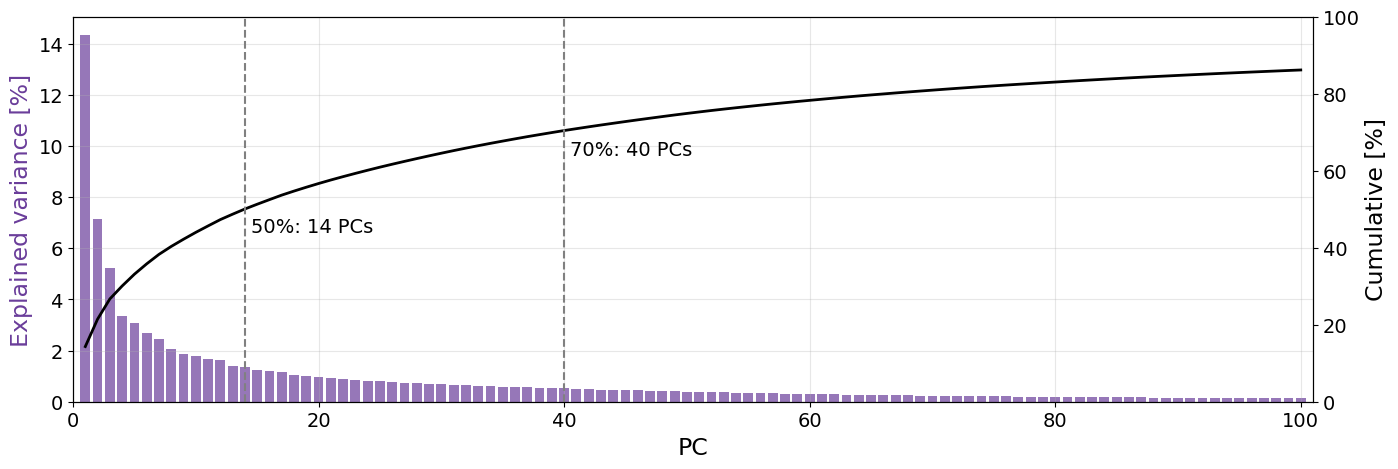

In [3]:
plot_explained_variance(pcs_indices.explained_variance_ratio.values, n_show=100);

### 1.2 Time series of the leading PCs

One panel per PC (first `N_PLOT`), with positive values in orange and negative values in purple. The label
gives the variance explained by each PC. The PCs are the amplitude of each EOF pattern in time: positive
values mean that the pattern appears with the sign shown in the EOF maps of notebook 01, negative values
mean the opposite pattern. The months removed in notebook 01 are simply joined by the line.

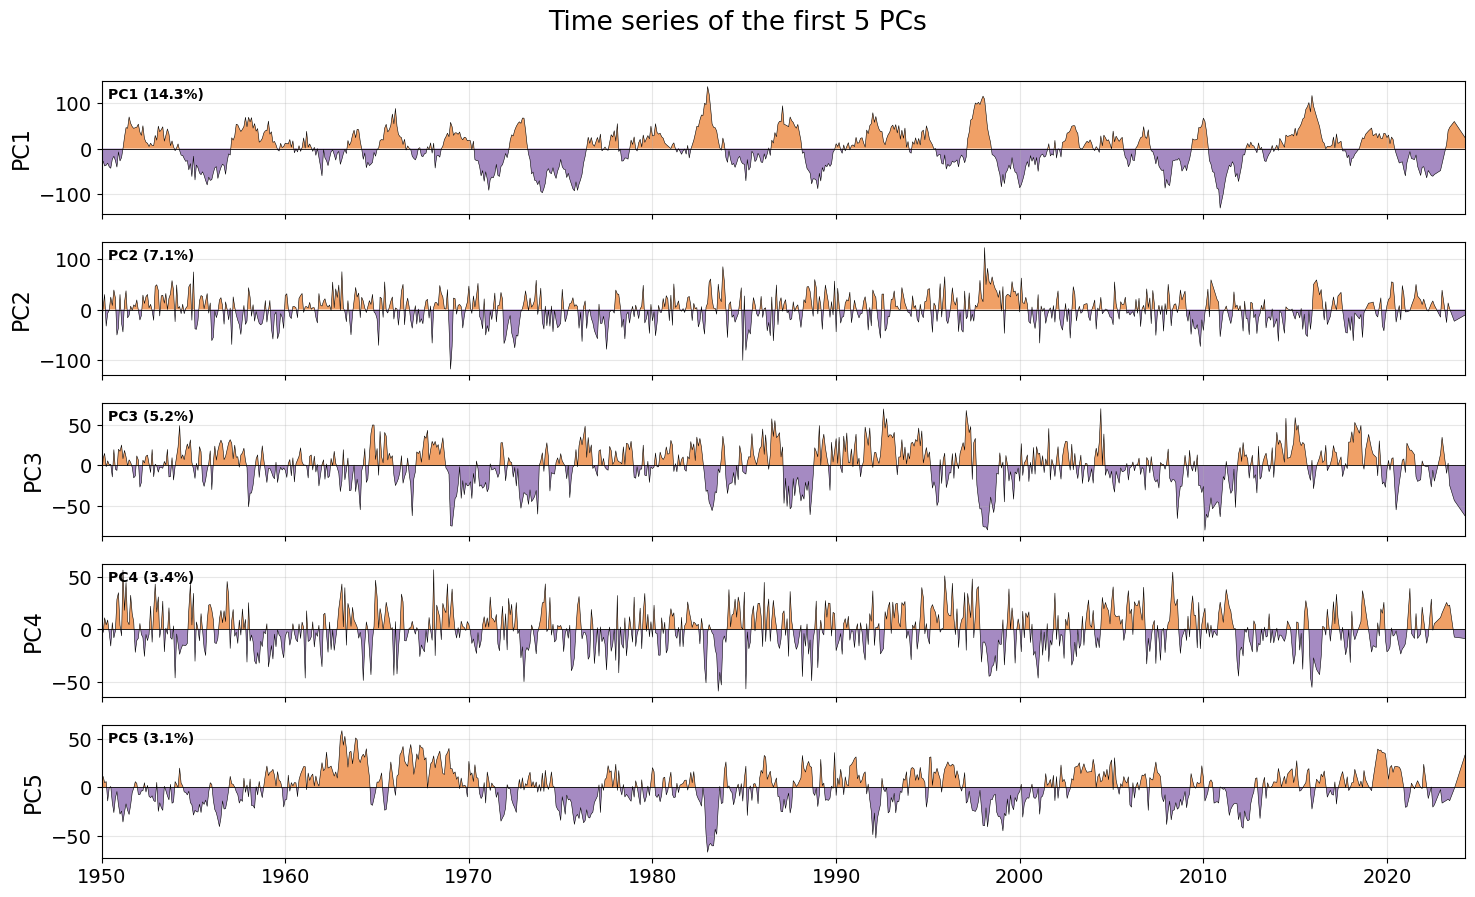

In [4]:
N_PLOT = 5  # number of leading PCs to plot

pcs_plot = pcs_indices.PCs.isel(n_pcs=slice(0, N_PLOT))
evr = pcs_indices.explained_variance_ratio.values
t = pcs_plot.time.values

fig, axs = plt.subplots(N_PLOT, 1, figsize=(15, 1.8 * N_PLOT), sharex=True, squeeze=False)
for k, ax in enumerate(axs[:, 0]):
    y = pcs_plot.isel(n_pcs=k).values
    ax.fill_between(t, 0, y, where=y >= 0, color=ORANGE, alpha=0.6, lw=0, interpolate=True)
    ax.fill_between(t, 0, y, where=y < 0, color=PURPLE, alpha=0.6, lw=0, interpolate=True)
    ax.plot(t, y, color='k', lw=0.4)
    ax.axhline(0, color='k', lw=0.6)
    ax.set_ylabel(f'PC{k + 1}')
    ax.text(0.005, 0.95, f'PC{k + 1} ({100 * evr[k]:.1f}%)', transform=ax.transAxes,
            va='top', fontsize=10, fontweight='bold')
    ax.grid(alpha=0.3)
axs[-1, 0].set_xlim(t[0], t[-1])
fig.suptitle(f'Time series of the first {N_PLOT} PCs', y=1.0)
fig.tight_layout()

## 2. Relationships between the indices

Before relating the indices with the PCs, it is useful to know how related the indices are among
themselves. The matrix shows the Pearson correlation between each pair of indices, computed over the
months where both are available (detrended indices).

- Only the lower triangle is shown (the matrix is symmetric) and the indices are grouped by region
  (`INDEX_GROUPS` in `utils/pcs_analysis.py`): ENSO, Pacific, North Atlantic and Southern Hemisphere.
- Orange: positive correlation, purple: negative. Values with |r| ≥ 0.5 are in bold and |r| < 0.1 in grey.

Strongly related indices (the ENSO block N34, RONI, ELI, OLR and SOI, or NAO and AO) are expected to be
reproduced by the same PCs, while indices almost uncorrelated with the rest (SCA, AMO, SAM) need their own
PCs.

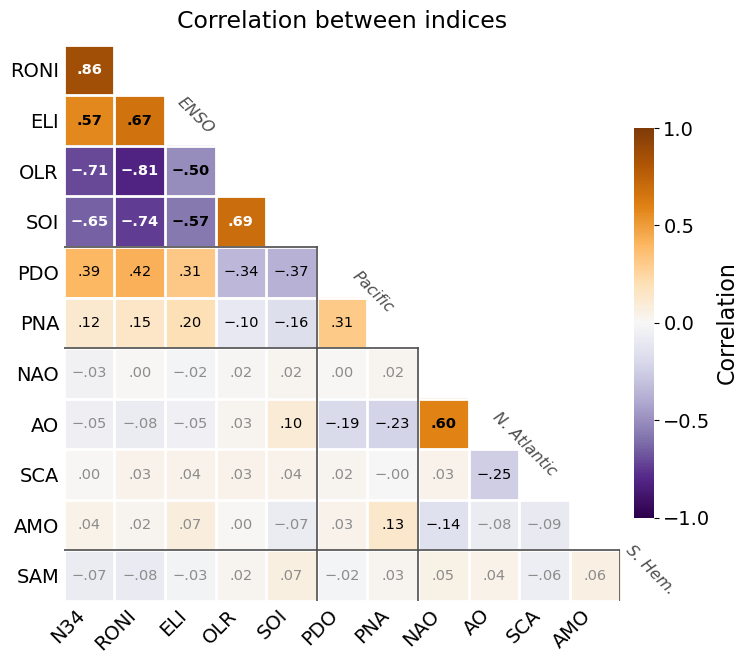

In [5]:
plot_index_correlation(index_correlation_matrix(pcs_indices));

## 3. Correlation of each index with each PC

Each cell is the Pearson correlation between one index (rows) and one of the first 30 PCs (columns),
over the months where the index is available. Orange: positive, purple: negative (the colour scale
saturates at ±0.8).

How to read it: a single strong cell in a row (e.g. PC1 for the ENSO indices) means the index is a
leading mode of the SST + MSL variability and is captured by one PC; a row with many weak cells means the
index is spread over many PCs and is only reproduced by combining them (Sections 4 and 5).

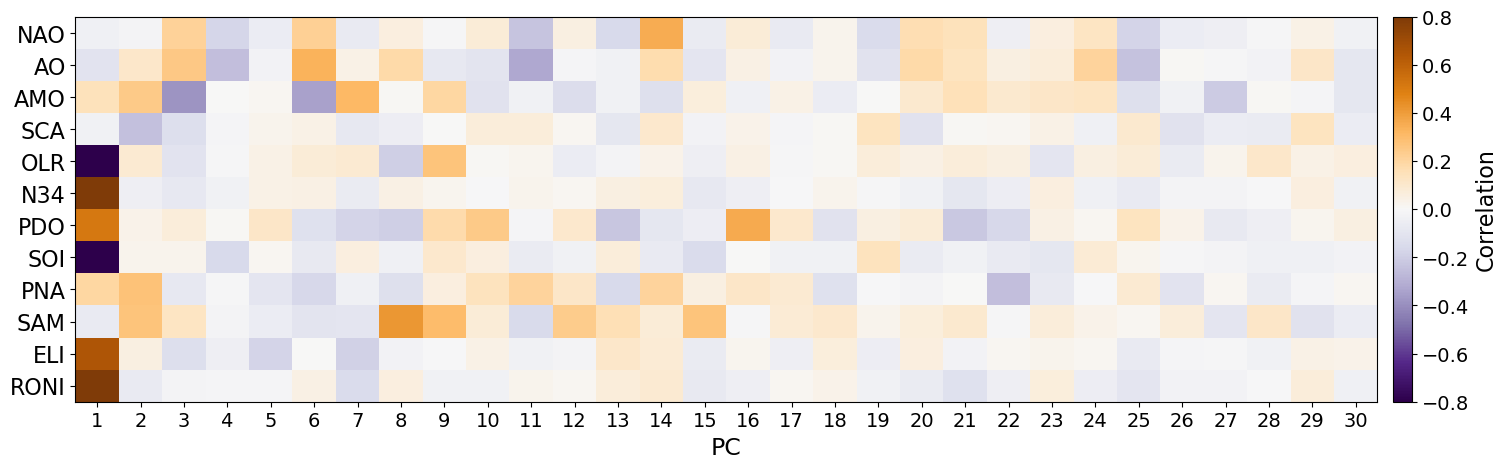

In [6]:
plot_pc_index_heatmap(pc_index_correlation(pcs_indices, n_pcs=30));

For each index, the three PCs with the highest absolute correlation among the first 100, with the sign
of the correlation:

In [7]:
top_pcs_table(pcs_indices, n_pcs=100, k=3)

,#1,#2,#3
NAO,PC14 (+0.35),PC11 (-0.23),PC6 (+0.22)
AO,PC6 (+0.33),PC11 (-0.33),PC3 (+0.25)
AMO,PC3 (-0.39),PC6 (-0.34),PC7 (+0.32)
SCA,PC2 (-0.25),PC68 (-0.17),PC3 (-0.13)
OLR,PC1 (-0.82),PC9 (+0.27),PC8 (-0.19)
N34,PC1 (+0.82),PC21 (-0.09),PC3 (-0.09)
PDO,PC1 (+0.52),PC16 (+0.36),PC10 (+0.25)
SOI,PC1 (-0.81),PC4 (-0.16),PC15 (-0.14)
PNA,PC2 (+0.28),PC22 (-0.25),PC11 (+0.21)
SAM,PC8 (+0.41),PC9 (+0.30),PC2 (+0.27)


## 4. Regression with all the PCs (in-sample)

Each index is regressed on all the $N = 100$ stored PCs (ordinary least squares, using only the months
where the index is available):

$$\widehat{\text{index}}(t) = \hat\beta_0 + \sum_{k=1}^{N} \hat\beta_k \, PC_k(t),
\qquad (\hat\beta_0, \dots, \hat\beta_N) = \arg\min_{\beta} \sum_t \Big[\text{index}(t) - \beta_0 - \sum_{k=1}^{N} \beta_k \, PC_k(t)\Big]^2$$

and the skill is the Pearson correlation $r = \text{corr}\big(\text{index}(t), \widehat{\text{index}}(t)\big)$.

The figure shows this correlation for each index (one marker per index). It is the same value computed in
notebook 01.

> With 100 predictors, part of this correlation is obtained by chance (overfitting): any series regressed
> on 100 random predictors would get a non-zero correlation. Section 5 quantifies the real skill with
> cross-validation.

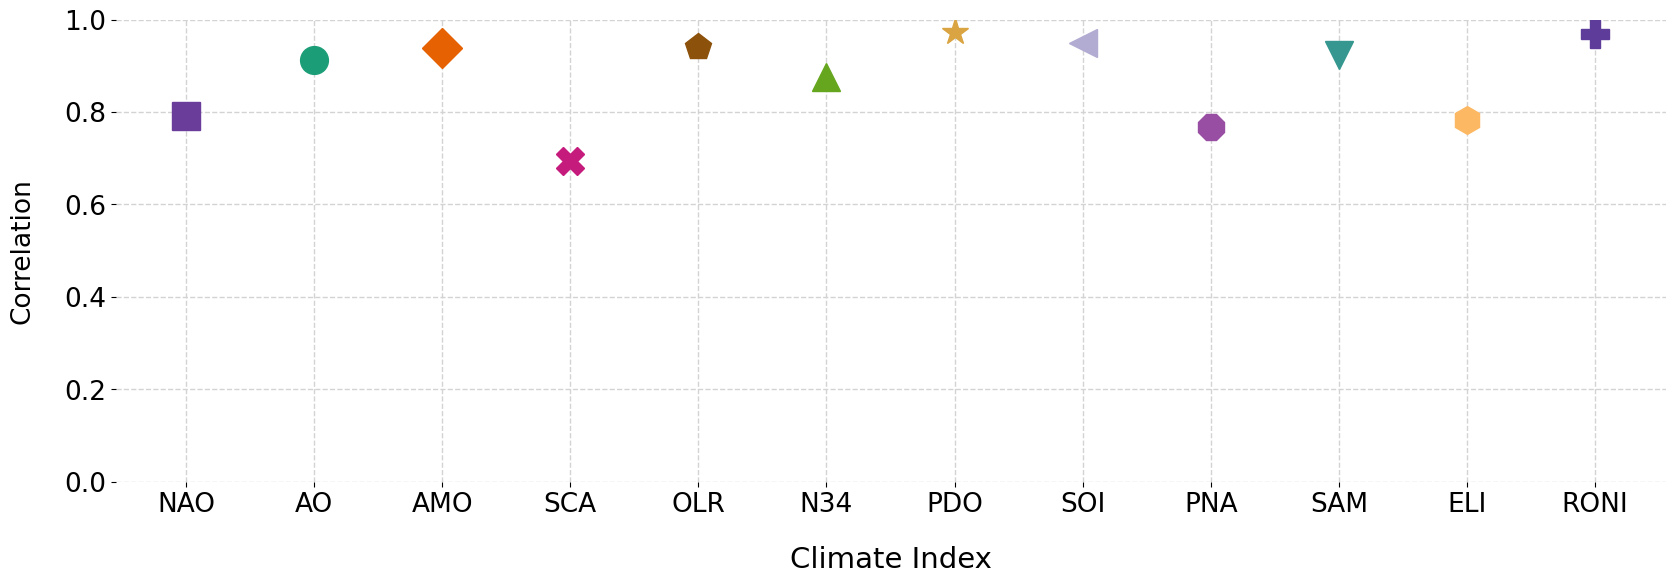

In [8]:
corr_all = dict(zip(pcs_indices.index_name.values.astype(str), pcs_indices.index_correlation.values))
plot_regression_summary(corr_all);

## 5. Regression skill vs number of PCs

The regression of Section 4 is repeated using only the first *n* PCs, for each *n* in `N_PCS`, and the
skill is measured in two ways:

- **In-sample**: the regression is fitted and evaluated on the same months. It always increases with *n*,
  even if the added PCs carry no information about the index.
- **Cross-validated**: the series is split into 5 contiguous blocks in time; each block is predicted with
  the model fitted on the other four. Contiguous blocks avoid that neighbouring (autocorrelated) months
  leak information between training and test. This is an honest estimate of the skill.

The comparison tells how many PCs are useful for each index: while the cross-validated skill increases
with *n*, the extra PCs add real information; when it stops increasing or decreases, the extra PCs only
add overfitting.

In [9]:
N_PCS = [3, 5, 10, 20, 30, 40, 50, 100]

skill = skill_vs_npcs(pcs_indices, N_PCS, n_splits=5, n_rep=100)

**In-sample** correlation for each index (one marker per index; darker = more PCs). The markers of each
index always go up with the number of PCs.

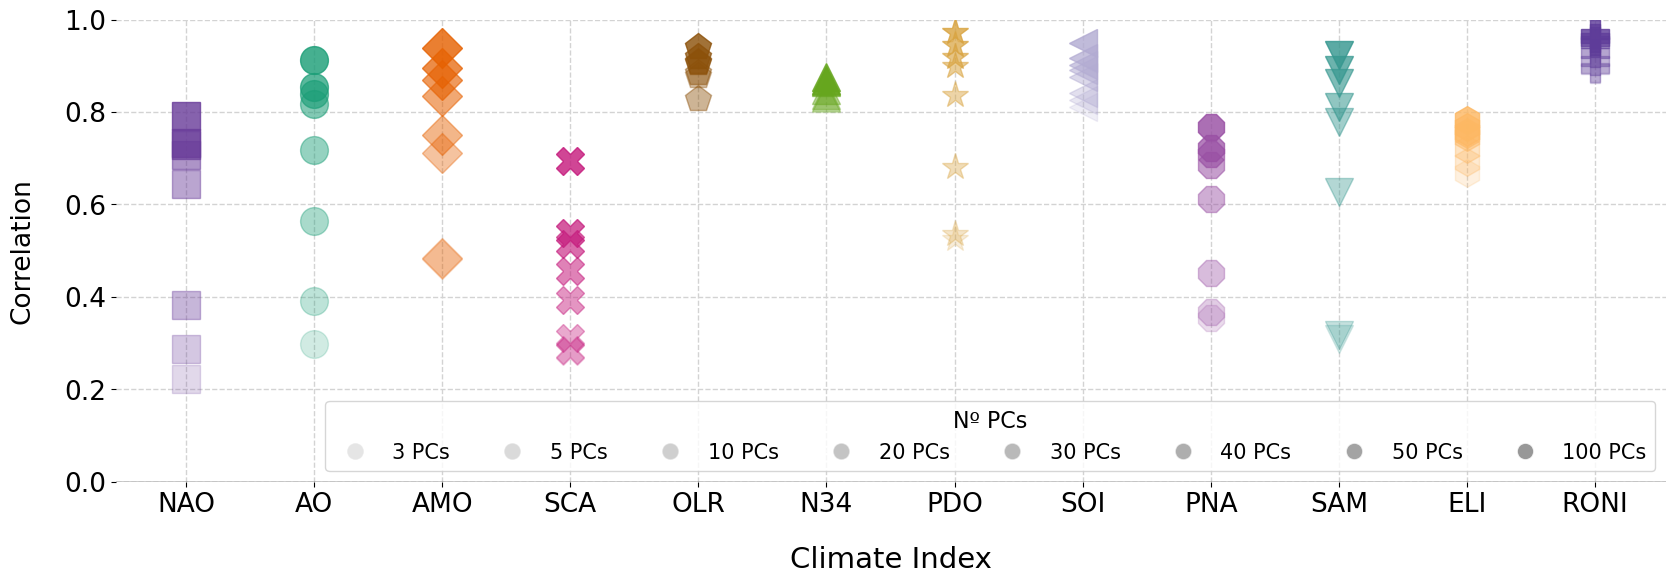

In [10]:
plot_regression_vs_npcs(skill.insample);

**Cross-validated** correlation for each index (darker = more PCs). Unlike the in-sample skill, it can
stay constant or decrease when PCs are added (e.g. ELI beyond 10 PCs or N34 beyond 30): the extra PCs
only add overfitting for those indices.

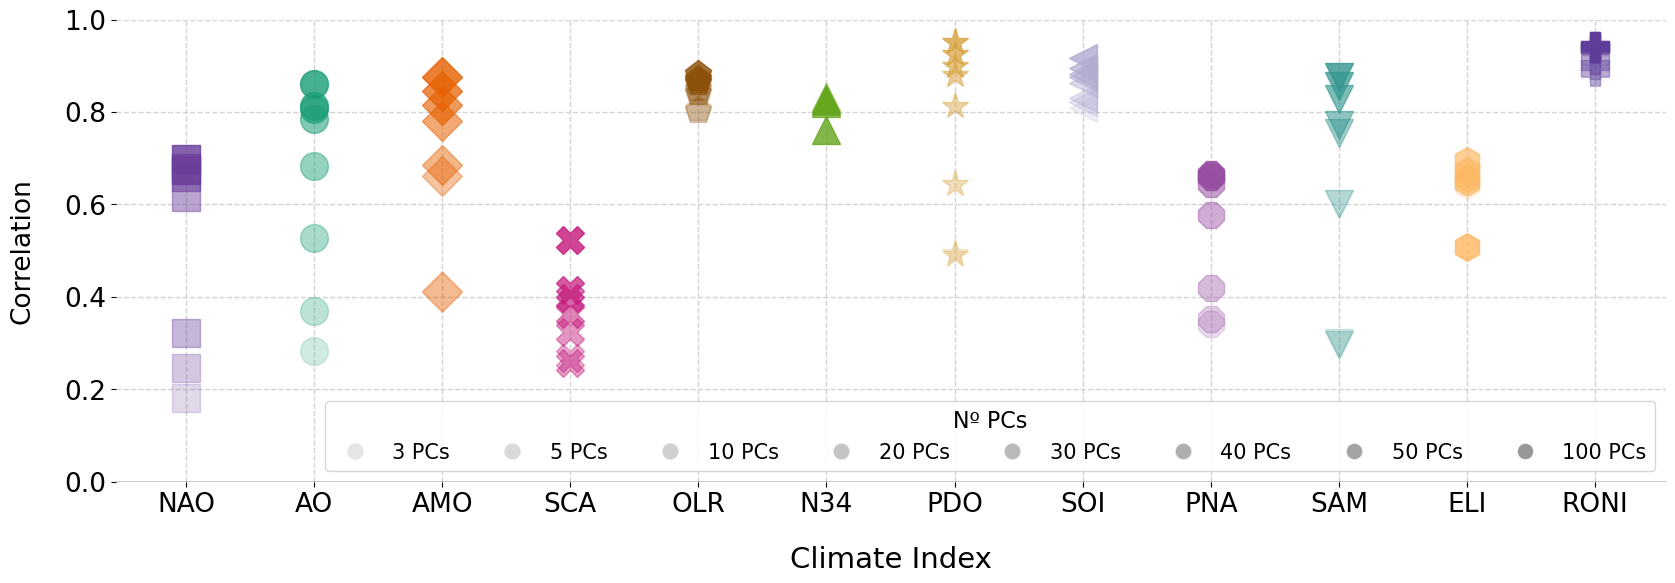

In [11]:
plot_regression_vs_npcs(skill.cv);

Same cross-validated correlations as a table (rows: number of PCs used, columns: index):

In [12]:
skill.cv.to_pandas().round(2)

climate_index,NAO,AO,AMO,SCA,OLR,N34,PDO,SOI,PNA,SAM,ELI,RONI
n_pcs_used,,,,,,,,,,,,
3,0.18,0.28,0.41,0.26,0.81,0.83,0.49,0.81,0.34,0.30,0.64,0.89
5,0.25,0.37,0.41,0.26,0.80,0.83,0.49,0.82,0.35,0.29,0.67,0.89
10,0.32,0.53,0.66,0.27,0.85,0.83,0.64,0.83,0.42,0.60,0.69,0.90
20,0.62,0.68,0.69,0.32,0.84,0.82,0.81,0.86,0.58,0.76,0.69,0.91
30,0.66,0.79,0.78,0.36,0.87,0.83,0.88,0.87,0.64,0.77,0.67,0.94
40,0.68,0.81,0.82,0.40,0.86,0.83,0.90,0.88,0.66,0.83,0.66,0.94
50,0.67,0.81,0.85,0.42,0.87,0.82,0.93,0.89,0.67,0.86,0.65,0.94
100,0.70,0.86,0.88,0.52,0.88,0.76,0.95,0.92,0.66,0.88,0.51,0.94


Number of PCs that gives the best cross-validated skill for each index, and that skill:

In [13]:
best = skill.cv.idxmax('n_pcs_used').astype(int)
best_skill = skill.cv.max('n_pcs_used')
xr.Dataset({'best_n_pcs': best, 'cv_corr': best_skill.round(2)}).to_dataframe()

,best_n_pcs,cv_corr
climate_index,,
NAO,100,0.70
AO,100,0.86
AMO,100,0.88
SCA,100,0.52
OLR,100,0.88
N34,30,0.83
PDO,100,0.95
SOI,100,0.92
PNA,50,0.67


## 6. Frequency analysis of the PCs

At which time scales does each PC vary? The PCs are computed from **detrended and deseasonalized**
anomalies, so the mean annual cycle has been removed; what is left is variability at intra-annual,
interannual and decadal scales.

The Fourier analysis needs a regular monthly series: the months removed as anomalous in notebook 01 are
filled by linear interpolation (`n_filled` below).

The variance of each PC is split into three period bands (`BANDS`, editable):

| Band | Periods | Typical processes |
|---|---|---|
| Intra-annual | 2 months – 1 yr | month-to-month weather noise, residual changes of the seasonal cycle |
| Interannual | 1–8 yr | ENSO (2–7 yr), QBO, IOD |
| Decadal | > 8 yr | PDO / IPO, AMO, residual of the quadratic detrending |

The intra-annual band is not the seasonal cycle (removed in notebook 01). With monthly data it is mostly
the weather noise that survives the monthly average (a month only contains ~6–10 independent synoptic
events), plus year-to-year changes of the seasonal cycle and signals phase-locked to the season (e.g.
ENSO peaking in boreal winter). Intraseasonal oscillations such as the MJO (30–60 days) are strongly
damped by the monthly average. The 12-month period itself is counted in the interannual band.

Monthly climate anomalies are *red*: persistence alone puts energy at long periods. Each band is
therefore compared with the fraction expected for a **red noise** (AR(1)) process with the same lag-1
autocorrelation as the PC. A ratio observed / red noise > 1 means more energy in that band than
persistence alone would give.

Contents of this section:
- **6.1** Fraction of the variance of each PC in each band, compared with red noise.
- **6.2** Time series of the leading PCs with their interannual and decadal components.
- **6.3** Seasonal modulation of the amplitude of each PC and its significance.

In [14]:
pcs_reg, n_filled = regular_monthly_pcs(pcs_indices, n_pcs=100)
print(f'{pcs_reg.sizes["time"]} months, {n_filled} filled by interpolation')

bv = band_variance(pcs_reg, BANDS)

892 months, 39 filled by interpolation


### 6.1 Variance of each PC by band

- **Top**: fraction of the variance of each of the first 30 PCs in each band (stacked bars, they add up
  to 1). Green: intra-annual, purple: interannual, orange: decadal. The black marks are the band limits of
  the equivalent red noise: the lower mark is the intra-annual fraction expected for red noise and the
  upper mark the intra-annual + interannual fraction. If the purple segment is longer than the space
  between the two marks, the PC has more interannual variance than red noise; if the orange segment
  starts below the upper mark, it has excess decadal variance.
- **Bottom**: ratio observed / red noise for each band (log2 scale: 2¹ = twice the red-noise energy,
  2⁻¹ = half). The fractions add up to 1, so an excess in one band forces a deficit in another.

> With ~74 years of data the decadal band contains only ~9 frequencies, so its ratio is noisy.
> This figure is descriptive: it does not include a significance test.

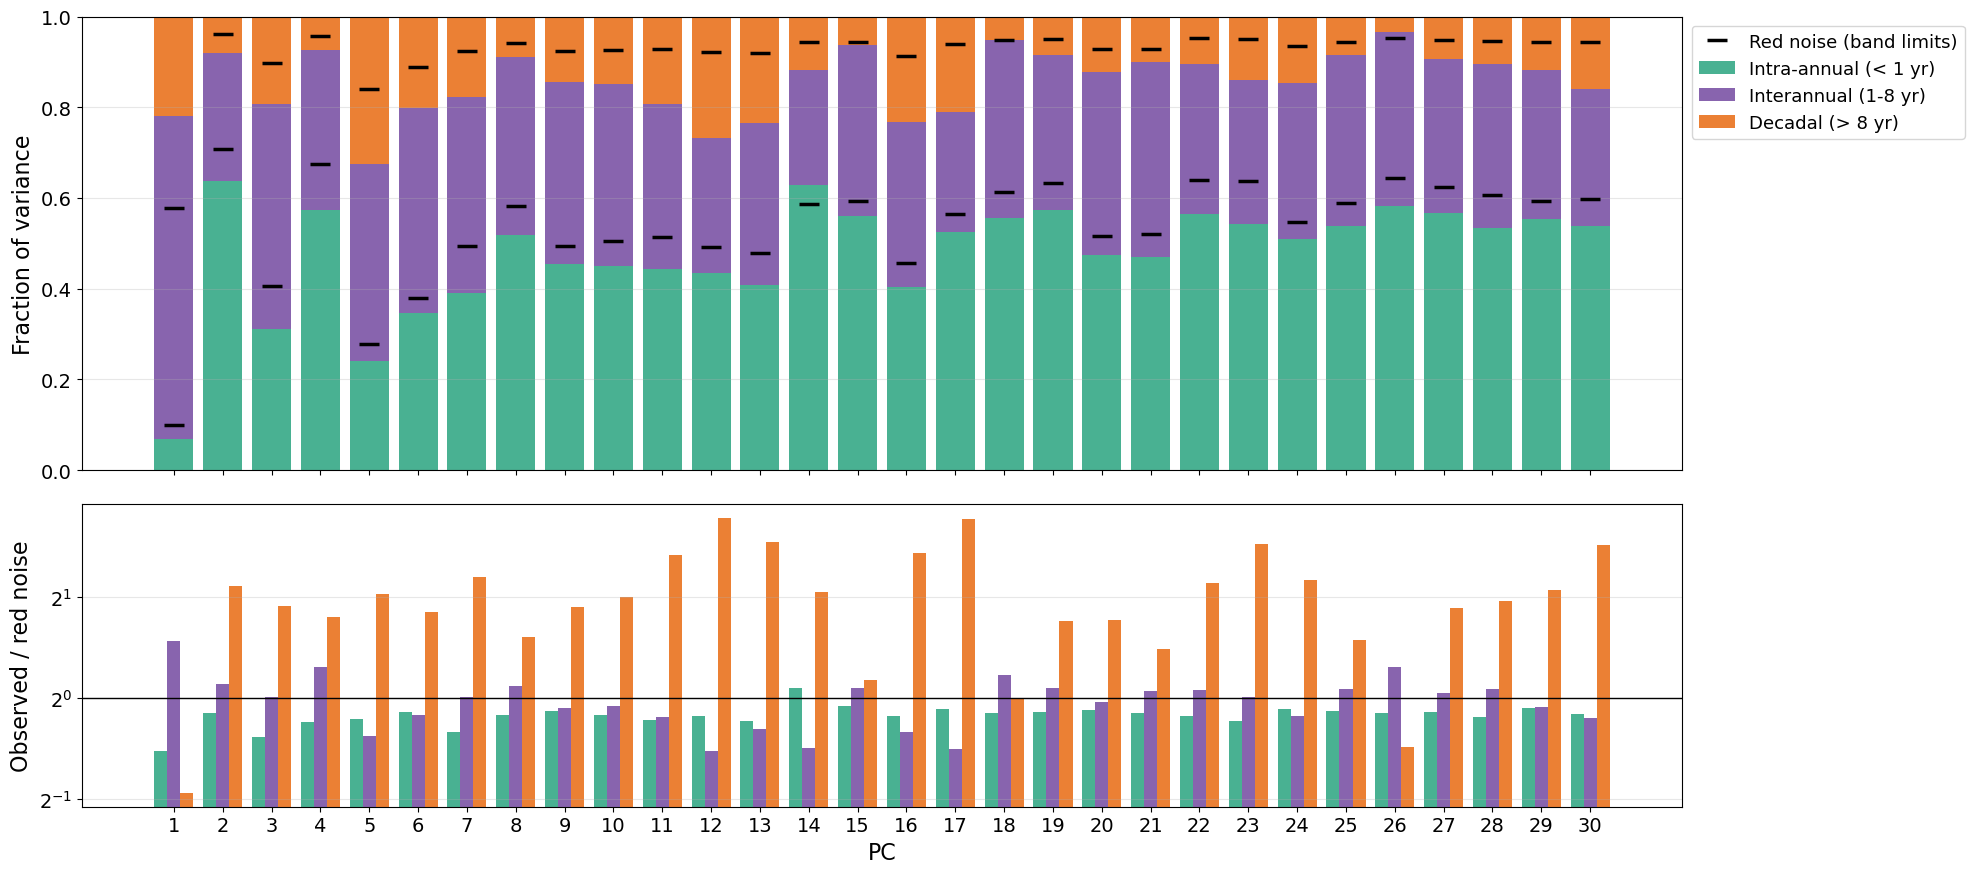

In [15]:
plot_band_fractions(bv, n_show=30);

Same fractions as a table for the first 20 PCs, with the dominant band and the lag-1 autocorrelation
(r1), which sets the red-noise reference: the higher r1, the more low-frequency variance is expected from
persistence alone.

In [16]:
df_bands = bv.fraction.to_pandas().round(2)
df_bands['dominant'] = bv.fraction.idxmax('band').values
df_bands['lag-1 autocorr.'] = bv.r1.round(2).values
df_bands.index = [f'PC{p}' for p in df_bands.index]
df_bands.head(20)

band,Intra-annual (< 1 yr),Interannual (1-8 yr),Decadal (> 8 yr),dominant,lag-1 autocorr.
PC1,0.07,0.71,0.22,Interannual (1-8 yr),0.92
PC2,0.64,0.28,0.08,Intra-annual (< 1 yr),0.30
PC3,0.31,0.50,0.19,Interannual (1-8 yr),0.67
PC4,0.57,0.35,0.07,Intra-annual (< 1 yr),0.36
PC5,0.24,0.43,0.33,Interannual (1-8 yr),0.78
PC6,0.35,0.45,0.20,Interannual (1-8 yr),0.69
PC7,0.39,0.43,0.18,Interannual (1-8 yr),0.58
PC8,0.52,0.39,0.09,Intra-annual (< 1 yr),0.49
PC9,0.45,0.40,0.14,Intra-annual (< 1 yr),0.58
PC10,0.45,0.40,0.15,Intra-annual (< 1 yr),0.57


### 6.2 Interannual and decadal components

Time series of the leading PCs (grey) with their **interannual** (1–8 yr, purple) and **decadal**
(> 8 yr, orange) components, obtained with an ideal Fourier band-pass filter (the Fourier coefficients
outside the band are set to zero). The intra-annual component is not drawn: it is the difference between
the grey series and the sum of the two coloured lines.

It shows when each PC is dominated by individual events (e.g. El Niño / La Niña in PC1) and when by slow
shifts of its mean level.

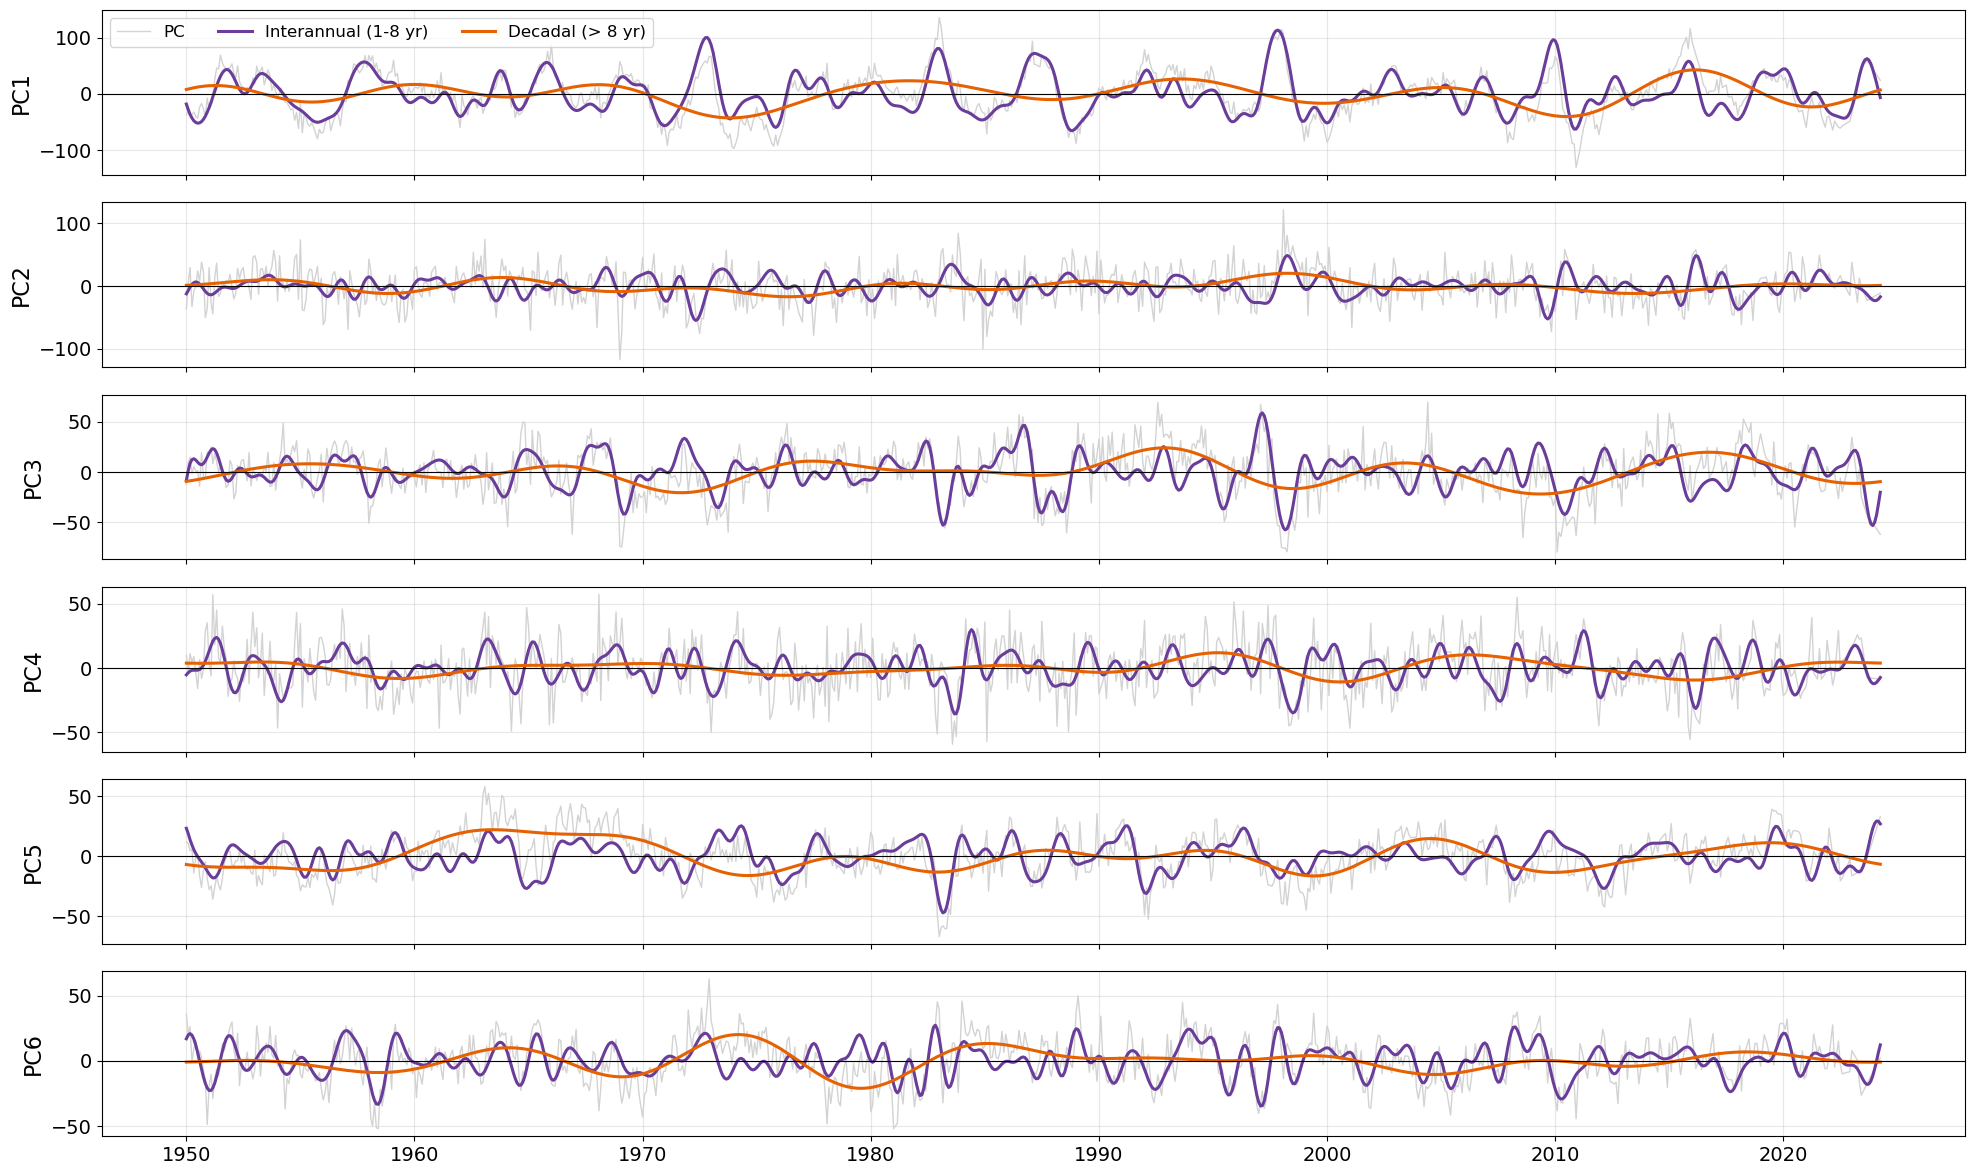

In [17]:
plot_band_decomposition(pcs_reg, pc_list=[1, 2, 3, 4, 5, 6]);

## Notes

- The indices are detrended (quadratic trend) because the PCs are computed from detrended fields. Without
  it, the long-term warming in AMO (NCEI ERSSTv5 North Atlantic SST anomaly, ~70% of its variance is
  trend over 1950–2024) and, to a lesser extent, in PDO and SAM cannot be reproduced by the PCs and their
  out-of-sample skill drops (AMO: from 0.88 to negative values). The skill is therefore that of the
  **detrended** indices.
- SAM (Marshall, BAS) ends in 2020 (see `00b_update_climate_indices.ipynb`).